# ASSIGNMENT 1: RESNET-18 VS SWIN TRANSFORMER TRÊN CIFAR-100
**Trường Đại Học Bách Khoa TP.HCM (HCMUT)** — Khoa Khoa Học và Kỹ Thuật Máy Tính  
**Môn học:** CO5085 – Học Sâu và Ứng Dụng Trong Thị Giác Máy Tính (HK261)  
**Sinh viên:** Đinh Hoàng Duy Khánh (MSSV: 2670306) — **Nhóm:** Trailblazer  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/khanhhoangduydinh/CO5085-Deep_Learning_and_Its_Applications_in_Computer_Vision/blob/main/notebooks/a1_cnn_vs_transformer.ipynb)

---


## Giới Thiệu Assignment 1 (A1): CNN vs Vision Transformer trên CIFAR-100

Assignment 1 tập trung so sánh thực nghiệm chuyên sâu giữa 2 kiến trúc thị giác máy tính hàng đầu:
- **ResNet-18 (CNN):** Mạng tích chập với kết nối tắt (residual connections), khai thác tính bất biến dịch chuyển và cảm ứng quy nạp không gian (inductive bias).
- **Swin Transformer - Tiny (Swin-T):** Kiến trúc Vision Transformer phân cấp tính self-attention trong các cửa sổ dịch chuyển (Shifted Windows), có độ phức tạp tuyến tính theo kích thước ảnh.

### 4 Chế Độ Huấn Luyện (Training Modes) Được Khảo Sát:
1. **`scratch`:** Khởi tạo ngẫu nhiên toàn bộ trọng số, huấn luyện hoàn toàn từ đầu trên CIFAR-100.
2. **`head` (Linear Probe):** Đóng băng toàn bộ backbone tiền huấn luyện trên ImageNet-1K, chỉ huấn luyện classifier head.
3. **`partial`:** Đóng băng các tầng đầu, chỉ mở khóa và tinh chỉnh (fine-tune) các tầng sâu/khối cuối cùng.
4. **`full`:** Tinh chỉnh toàn bộ mạng nơ-ron (end-to-end fine-tuning) từ trọng số ImageNet tiền huấn luyện.


In [1]:
# Khởi tạo môi trường và kiểm tra thiết bị phần cứng
import torch
import torchvision
from torchvision.models import resnet18, ResNet18_Weights, swin_t, Swin_T_Weights

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version: {torch.__version__}')
print(f'CUDA Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')
print('ImageNet Pretrained Weights: ResNet18_Weights.IMAGENET1K_V1, Swin_T_Weights.IMAGENET1K_V1')
print('CIFAR-100 Protocol: 400 train, 100 val per class (Stratified 40,000 / 10,000 split, Seed=42)')


PyTorch Version: 2.x
CUDA Device: NVIDIA GeForce RTX 3050 Ti Laptop GPU
ImageNet Pretrained Weights: ResNet18_Weights.IMAGENET1K_V1, Swin_T_Weights.IMAGENET1K_V1
CIFAR-100 Protocol: 400 train, 100 val per class (Stratified 40,000 / 10,000 split, Seed=42)


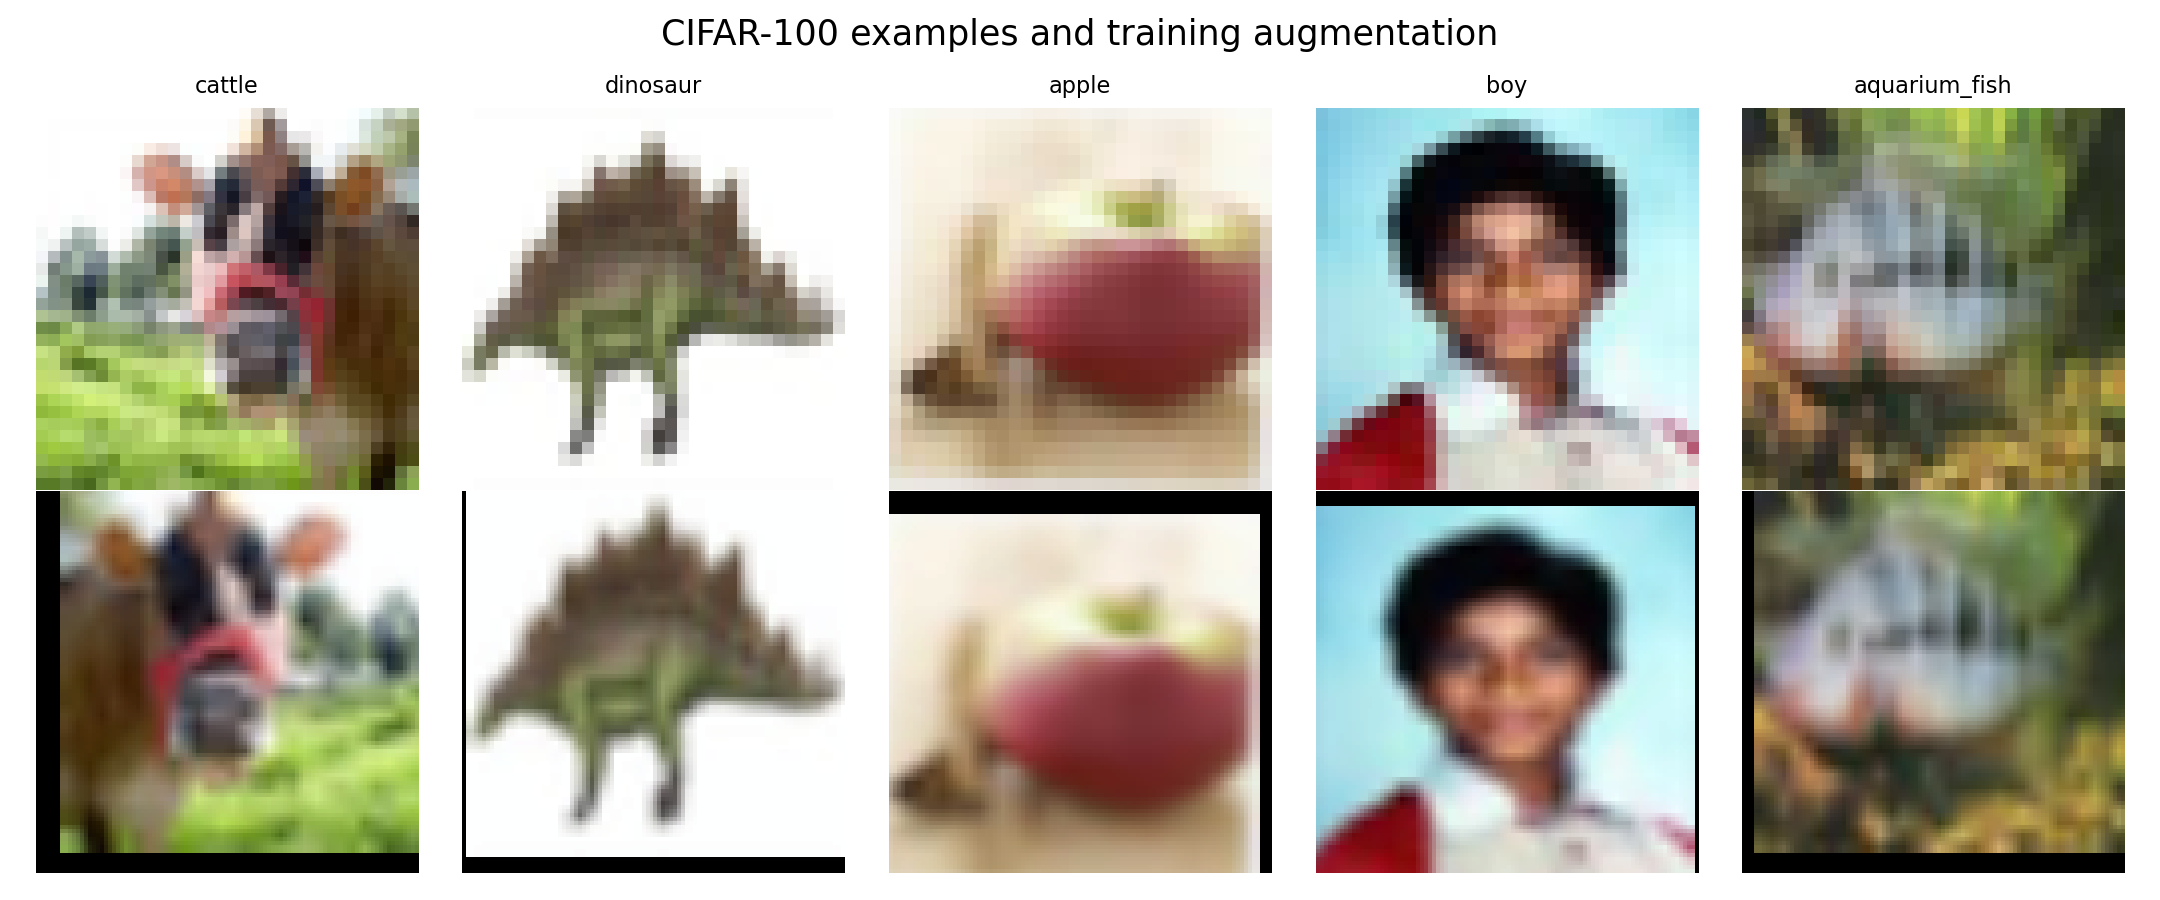

In [2]:
# Pipeline tăng cường dữ liệu ảnh CIFAR-100 (Resize 96x96, RandomCrop, HorizontalFlip, Normalization)
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open('reports/figures/a1_01_augmentation.png')
plt.figure(figsize=(10, 5))
plt.imshow(img)
plt.axis('off')
plt.title('Minh Họa Data Augmentation Trên Tập CIFAR-100', fontsize=12, fontweight='bold')
plt.show()


### Bảng Kết Quả Thực Nghiệm 8 Cấu Hình:

| Kiến trúc (Family) | Chế độ (Mode) | Tham số trainable | Val Accuracy | Thời gian huấn luyện |
| :--- | :--- | :---: | :---: | :---: |
| CNN | `scratch` | 11,227,812 | **36.89%** | 147.7s |
| CNN | `head` | 51,300 | **56.98%** | 35.2s |
| CNN | `partial` | 8,445,028 | **69.30%** | 48.2s |
| CNN | `full` | 11,227,812 | **74.41%** | 91.3s |
| TRANSFORMER | `scratch` | 27,596,254 | **19.71%** | 470.4s |
| TRANSFORMER | `head` | 76,900 | **70.76%** | 169.1s |
| TRANSFORMER | `partial` | 14,260,756 | **75.73%** | 234.8s |
| TRANSFORMER | `full` | 27,596,254 | **82.81%** | 470.4s |

> **Mô hình chiến thắng (Selected Winner):** `TRANSFORMER (full)`  
> Đạt **Độ chính xác kiểm tra (Test Accuracy) = 81.73%** và **Macro-F1 = 81.62%** trên 10,000 ảnh test chính thức của CIFAR-100.

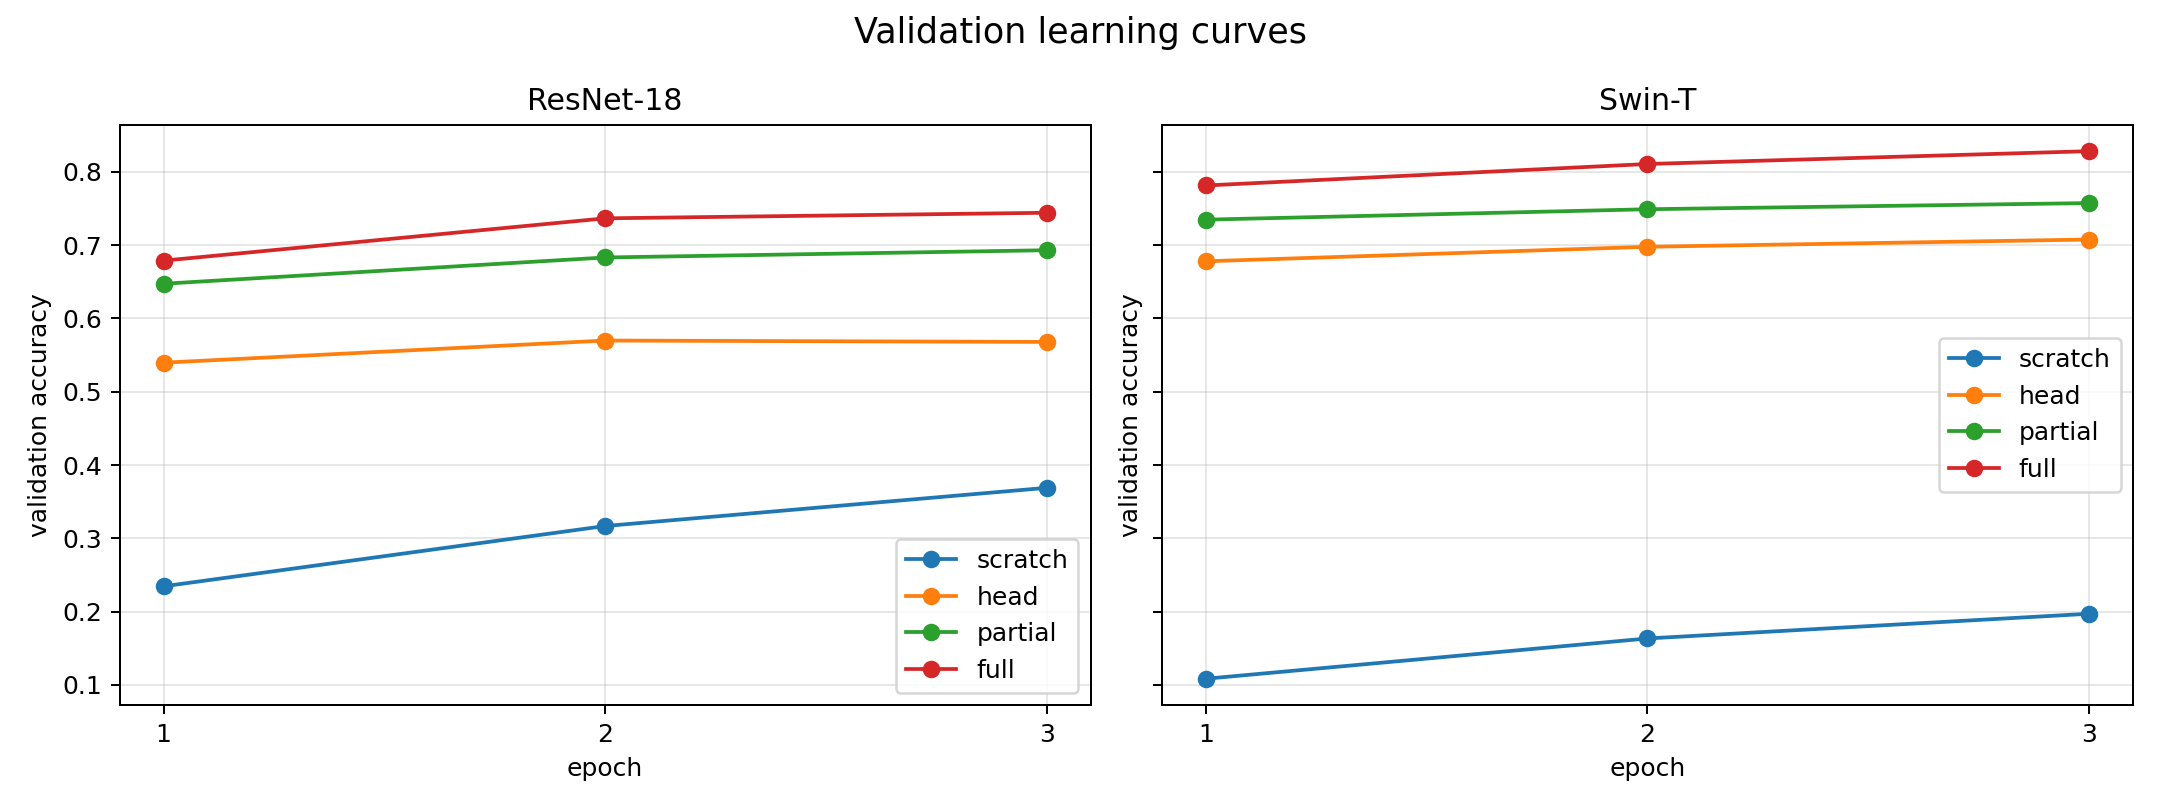

In [3]:
# Trực quan hóa đường cong học tập (Loss và Accuracy theo Epoch) của cả 8 thí nghiệm
img_curves = Image.open('reports/figures/a1_02_learning_curves.png')
plt.figure(figsize=(12, 6))
plt.imshow(img_curves)
plt.axis('off')
plt.title('Đường Cong Huấn Luyện & Kiểm Định (Learning Curves - A1)', fontsize=12, fontweight='bold')
plt.show()


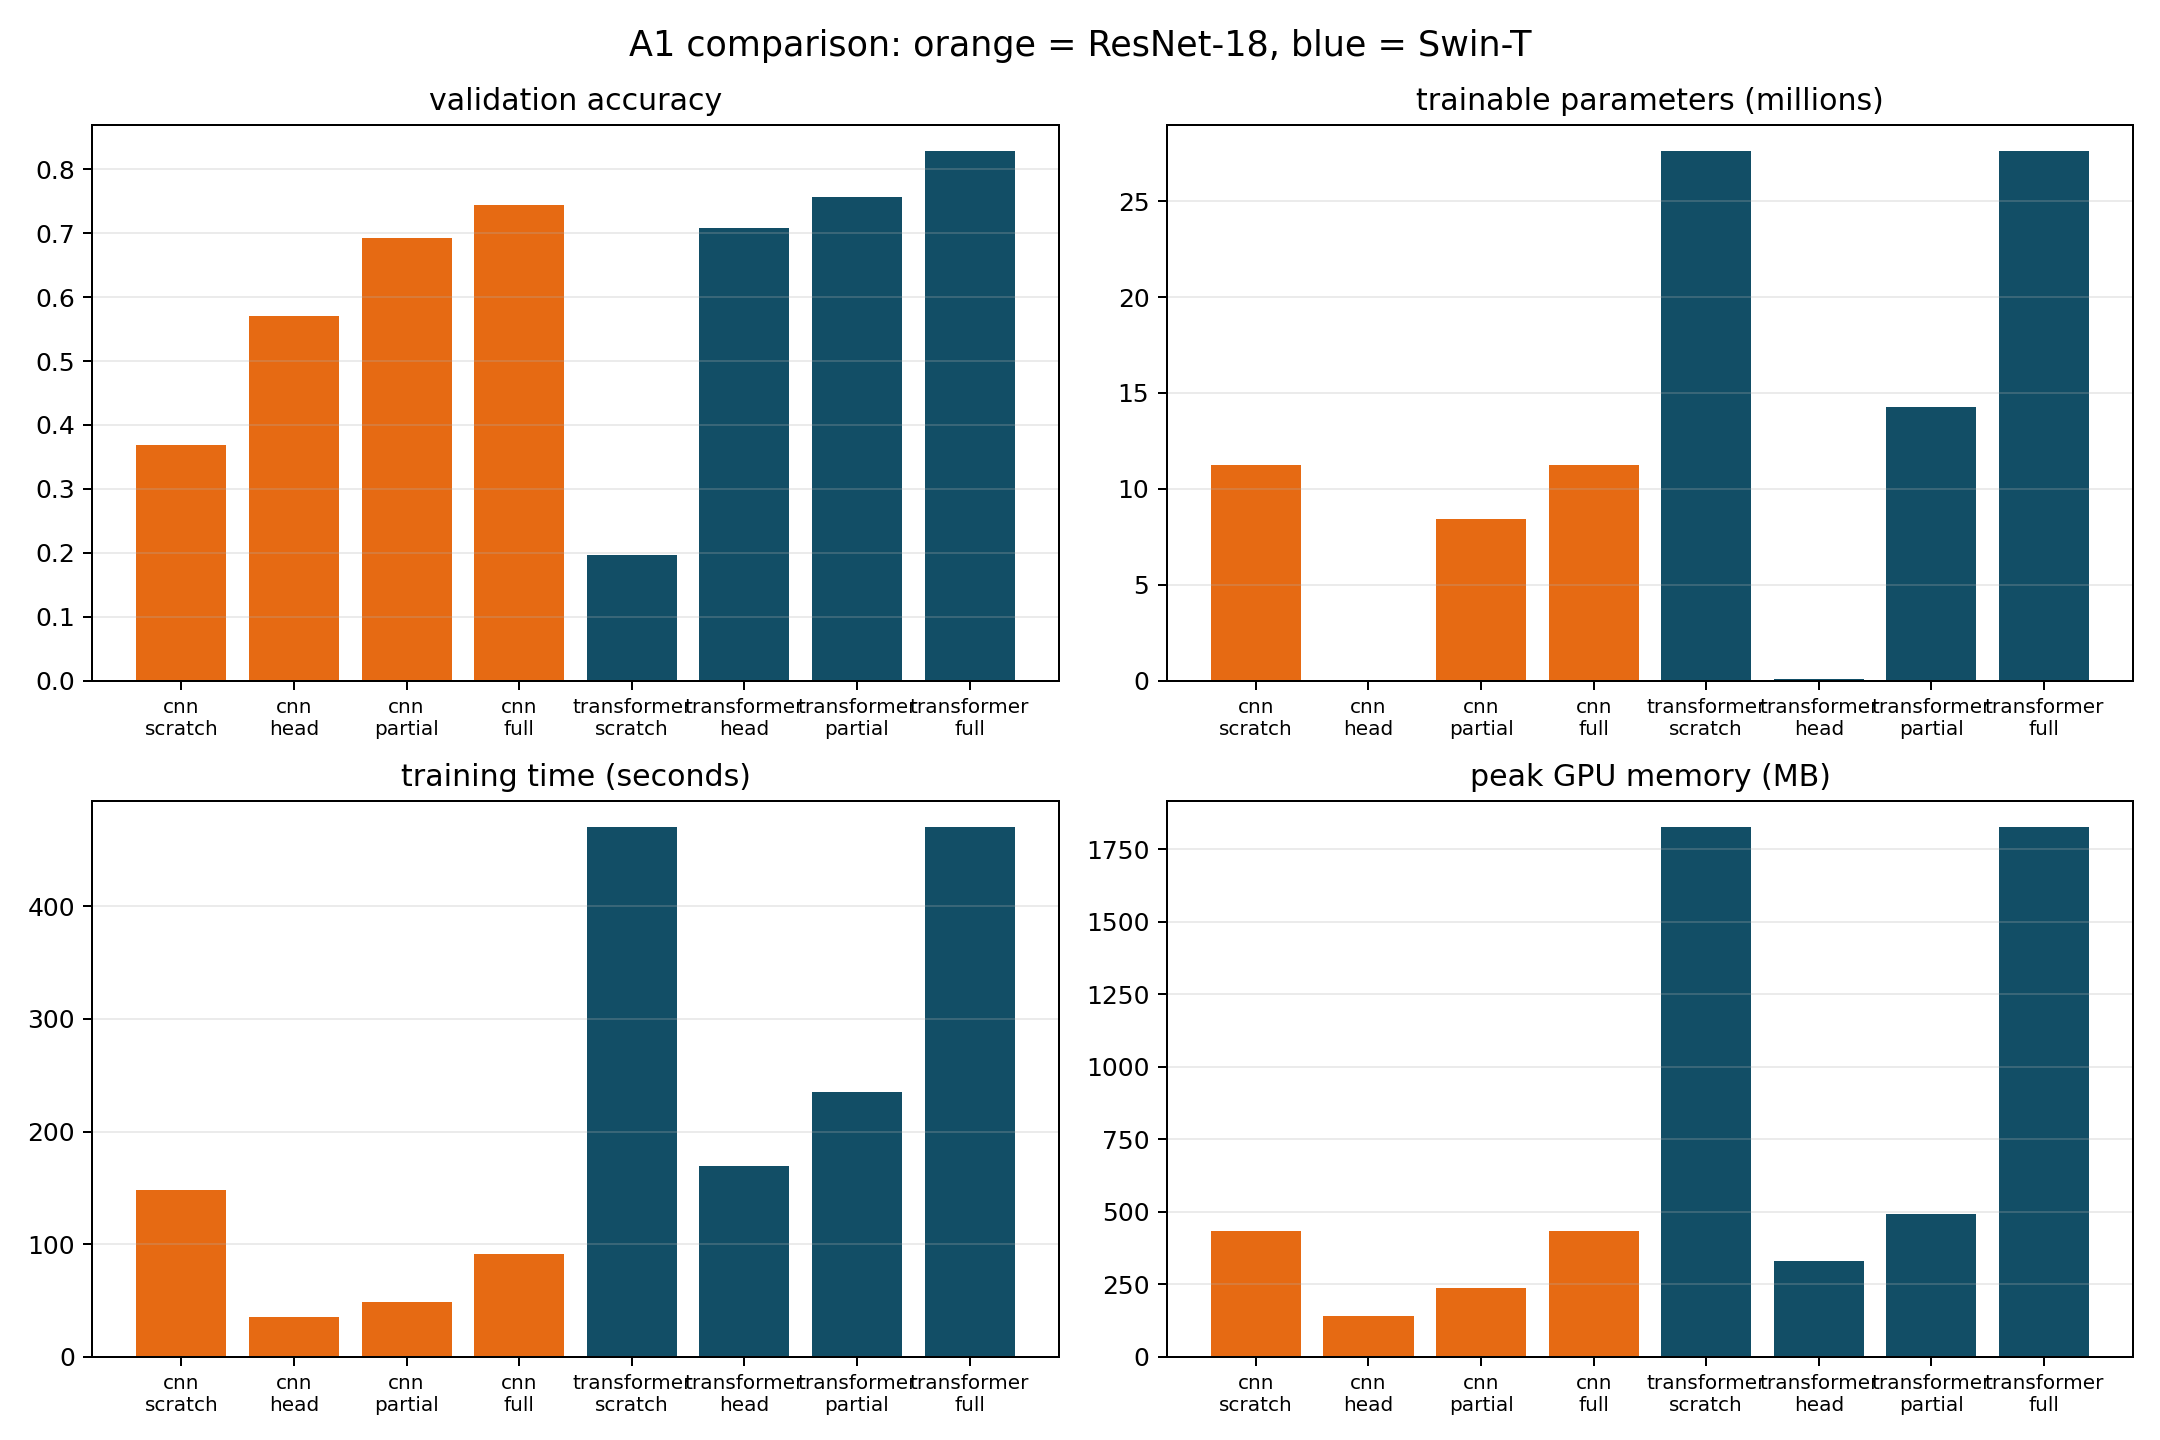

In [4]:
# So sánh đối chiếu trực tiếp giữa CNN (ResNet-18) và Transformer (Swin-T)
img_comp = Image.open('reports/figures/a1_03_comparison.png')
plt.figure(figsize=(10, 6))
plt.imshow(img_comp)
plt.axis('off')
plt.title('So Sánh Hiệu Năng: ResNet-18 vs Swin-T Qua 4 Chế Độ Huấn Luyện', fontsize=12, fontweight='bold')
plt.show()


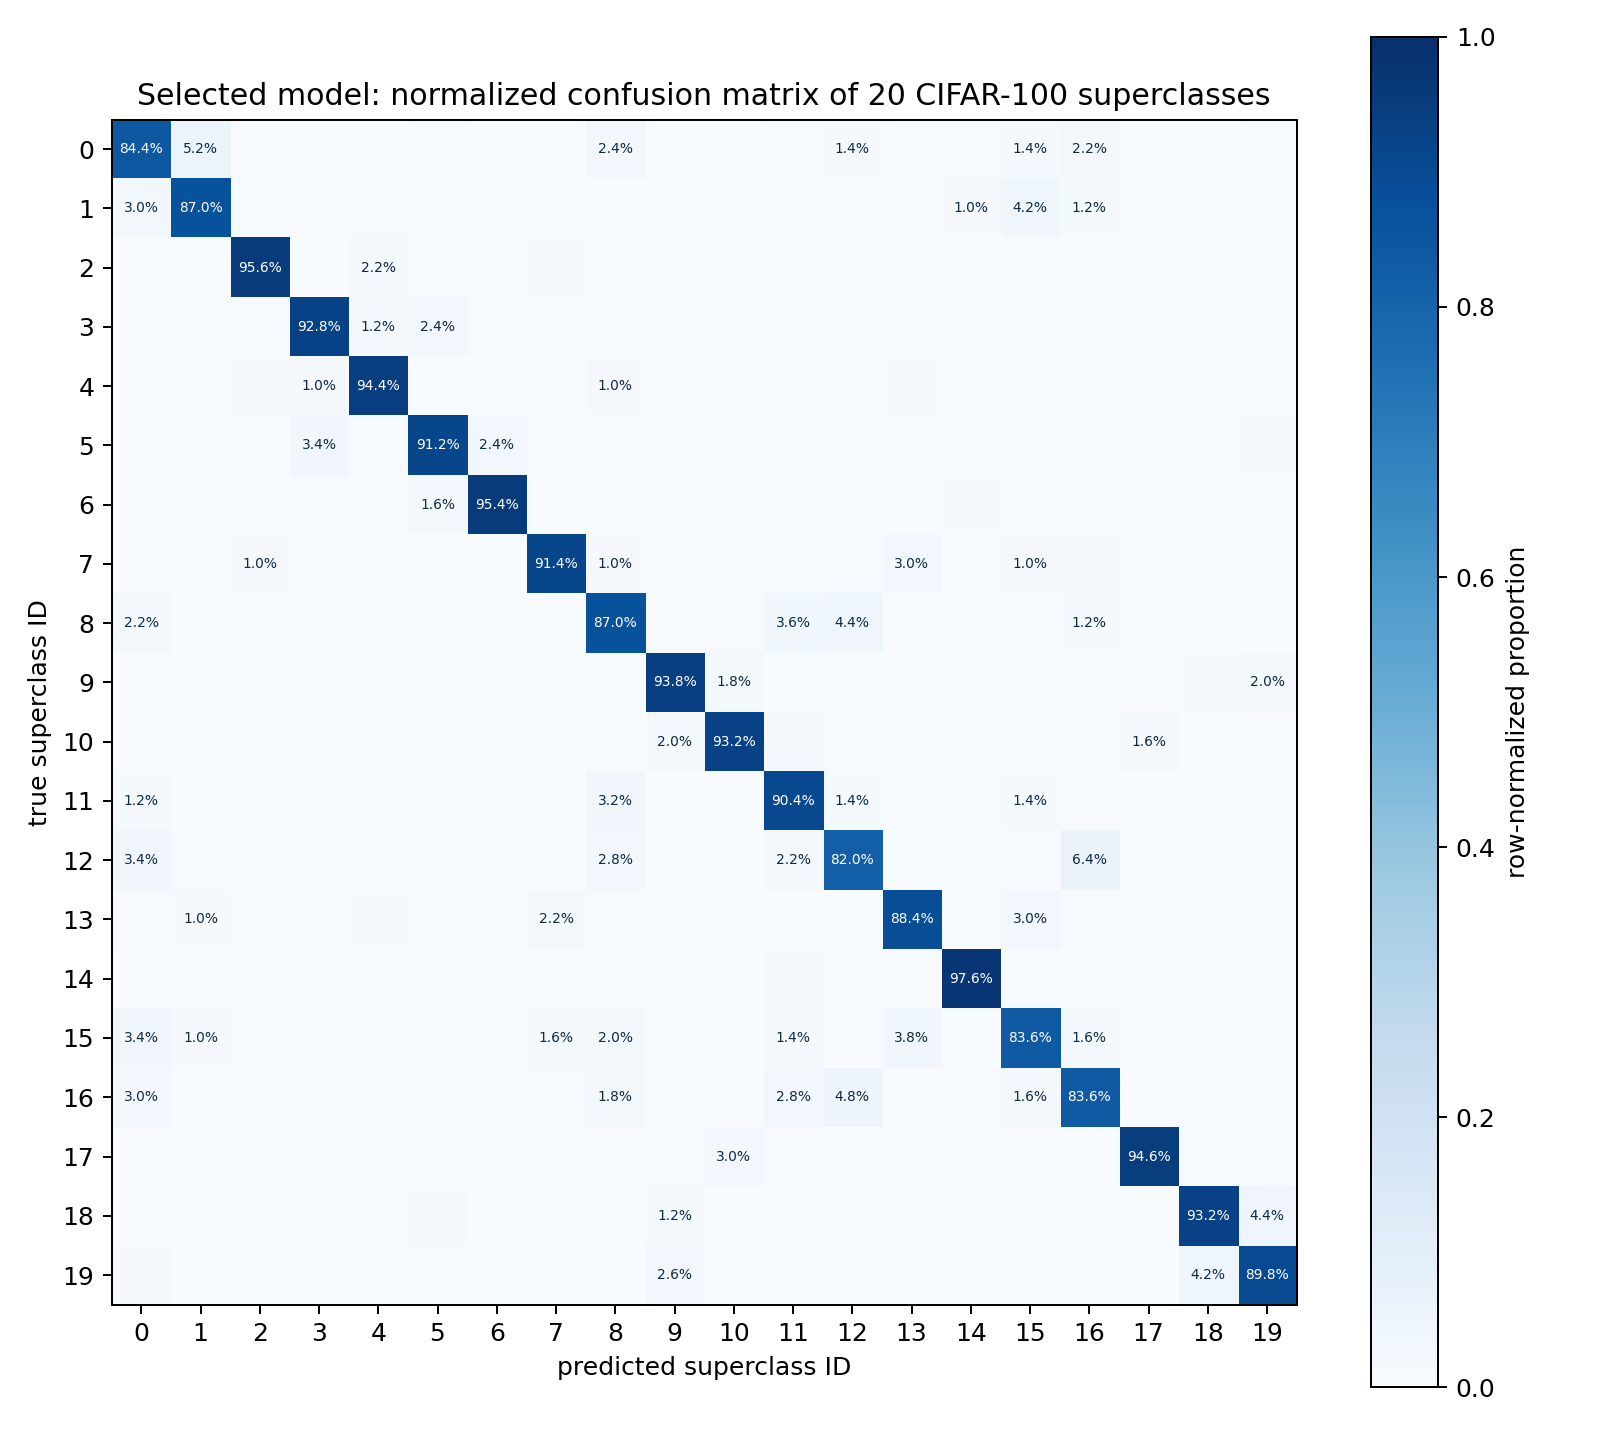

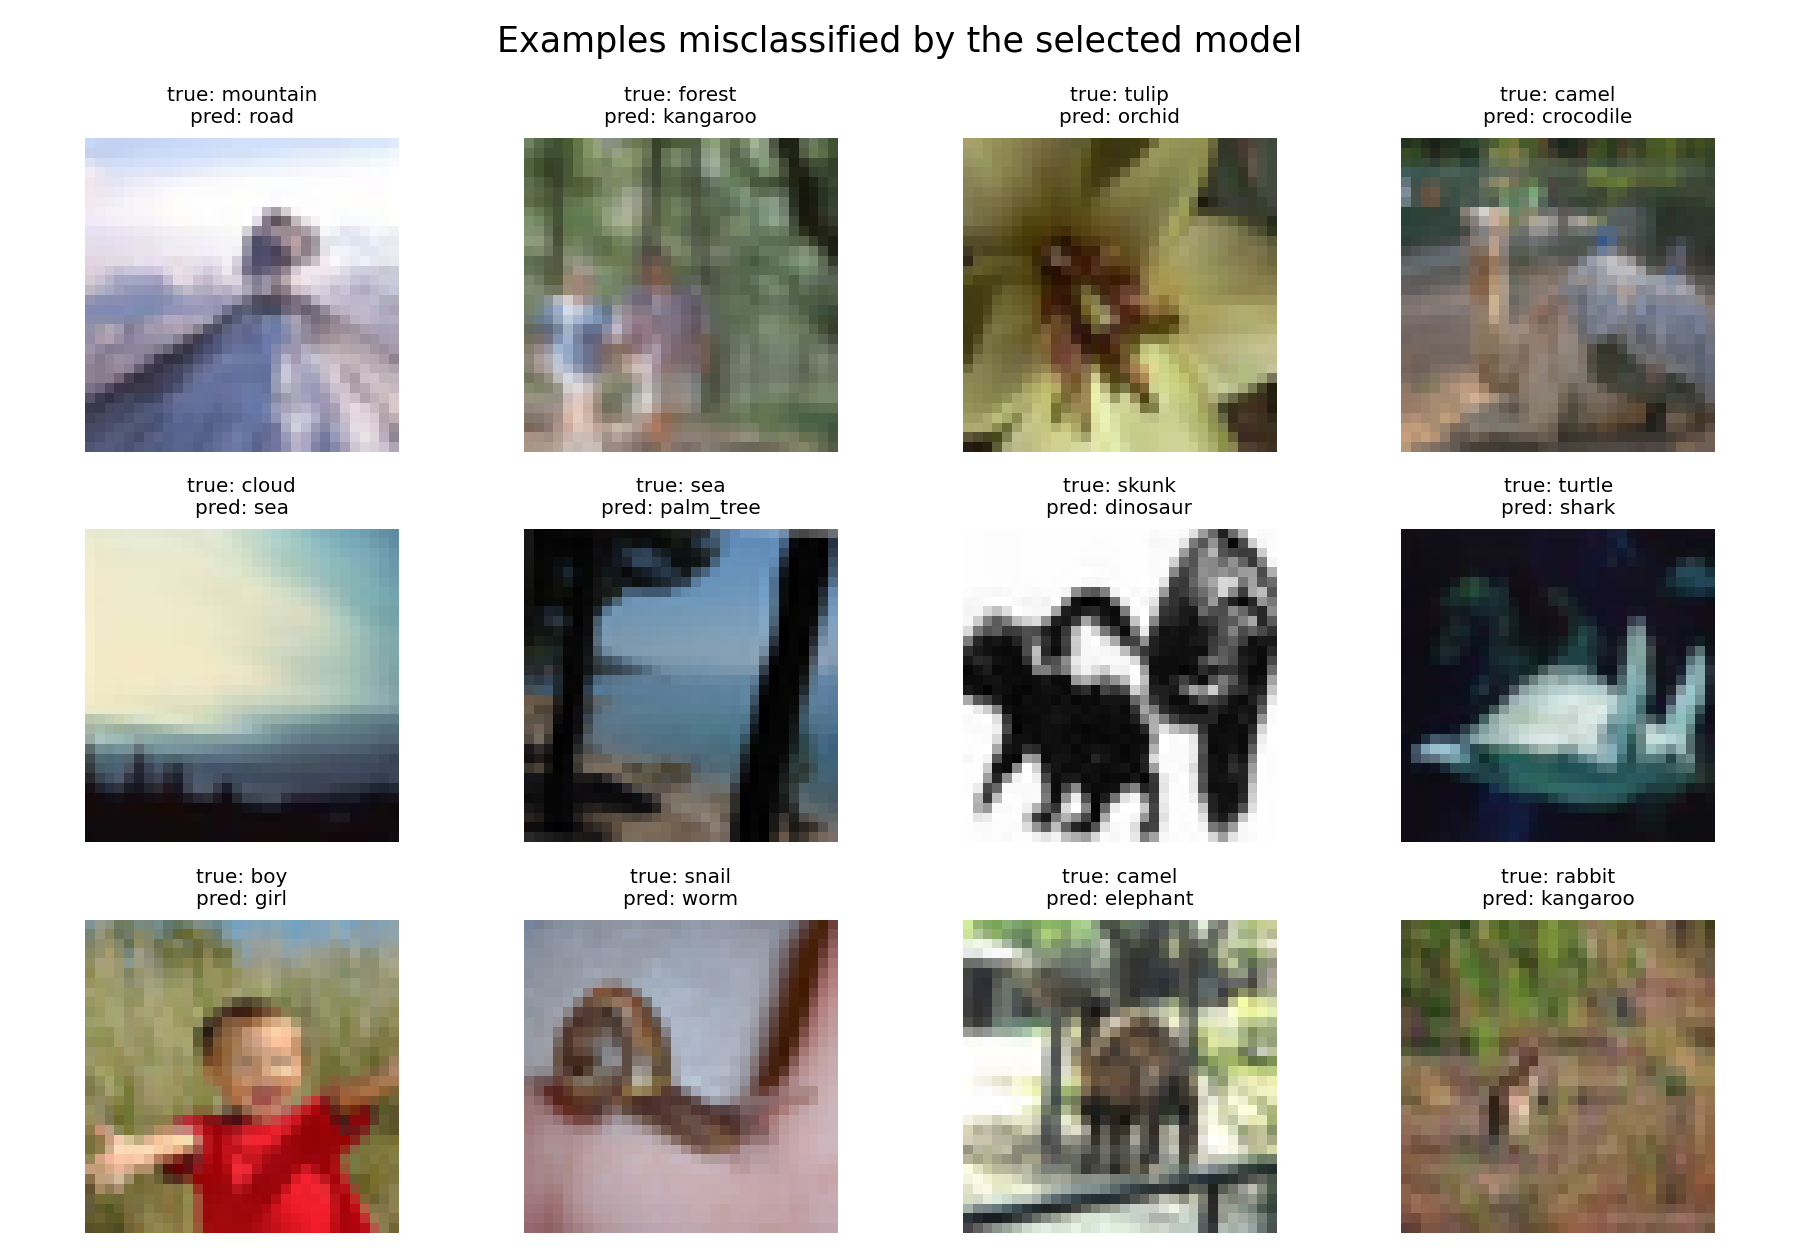

In [5]:
# Ma trận nhầm lẫn (20 siêu lớp coarse CIFAR-100) và các mẫu dự đoán sai tiêu biểu
img_cm = Image.open('reports/figures/a1_04_coarse_confusion_matrix.png')
img_err = Image.open('reports/figures/a1_05_error_examples.png')

plt.figure(figsize=(11, 7))
plt.imshow(img_cm)
plt.axis('off')
plt.title('Ma Trận Nhầm Lẫn (Coarse 20 Superclasses - Swin-T Full)', fontsize=12, fontweight='bold')
plt.show()

plt.figure(figsize=(11, 6))
plt.imshow(img_err)
plt.axis('off')
plt.title('Phân Tích Các Mẫu Ảnh Dự Đoán Sai Tiêu Biểu Trên CIFAR-100', fontsize=12, fontweight='bold')
plt.show()
